In [ ]:
import zipfile
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
zip_path = '/content/LungData.zip'
extract_path = '/content/'

print("Extracting dataset...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

data_dir = '/content/LungData'

Extracting dataset...


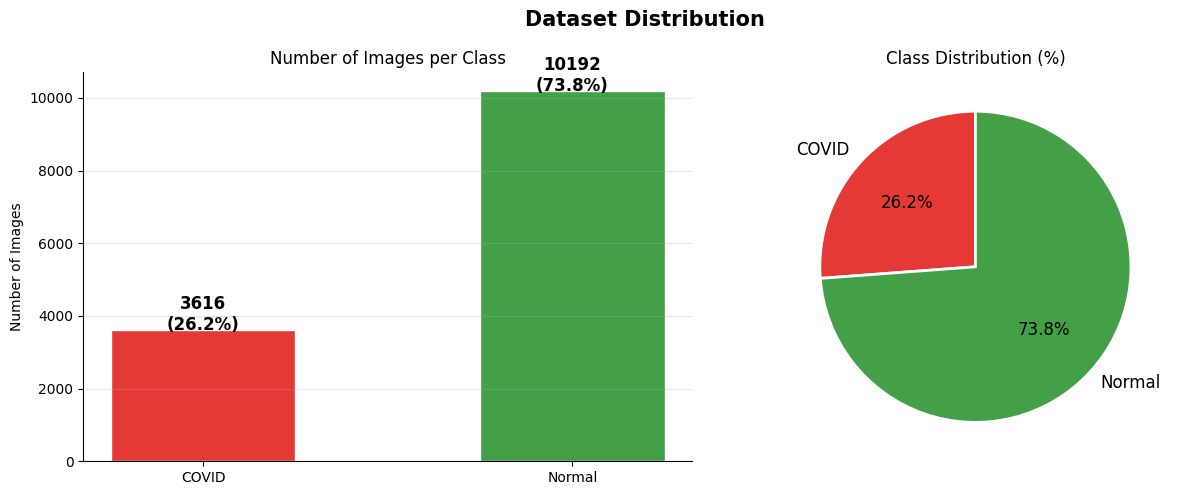

       DATASET SUMMARY
  COVID     : 3616 images (26.2%)
  Normal    : 10192 images (73.8%)
  TOTAL     : 13808 images


In [ ]:
import os
import matplotlib.pyplot as plt

class_counts = {}
for class_name in ['COVID', 'Normal']:
    class_path = os.path.join(data_dir, class_name, 'images')
    count = len([f for f in os.listdir(class_path)
                 if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    class_counts[class_name] = count

classes = list(class_counts.keys())
counts  = list(class_counts.values())
total   = sum(counts)
colors  = ['#E53935', '#43A047']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Dataset Distribution', fontsize=15, fontweight='bold')

# Bar Plot
bars = axes[0].bar(classes, counts, color=colors, width=0.5, edgecolor='white')
for bar, count in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 8,
                 f'{count}\n({count/total*100:.1f}%)',
                 ha='center', fontsize=12, fontweight='bold')
axes[0].set_title('Number of Images per Class')
axes[0].set_ylabel('Number of Images')
axes[0].grid(axis='y', alpha=0.3)
axes[0].spines[['top', 'right']].set_visible(False)

# Pie Chart
axes[1].pie(counts, labels=classes, colors=colors,
            autopct='%1.1f%%', startangle=90,
            wedgeprops=dict(edgecolor='white', linewidth=2),
            textprops={'fontsize': 12})
axes[1].set_title('Class Distribution (%)')

plt.tight_layout()
plt.show()

print("=" * 35)
print("       DATASET SUMMARY")
print("=" * 35)
for cls, cnt in class_counts.items():
    print(f"  {cls:10s}: {cnt:4d} images ({cnt/total*100:.1f}%)")
print(f"  {'TOTAL':10s}: {total:4d} images")
print("=" * 35)

In [ ]:
img_size = 128
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=123,
    image_size=(img_size, img_size), batch_size=batch_size)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=123,
    image_size=(img_size, img_size), batch_size=batch_size)

class_names = train_ds.class_names
print(f"Classes: {class_names}")

Found 27616 files belonging to 2 classes.
Using 22093 files for training.
Found 27616 files belonging to 2 classes.
Using 5523 files for validation.
Classes: ['COVID', 'Normal']


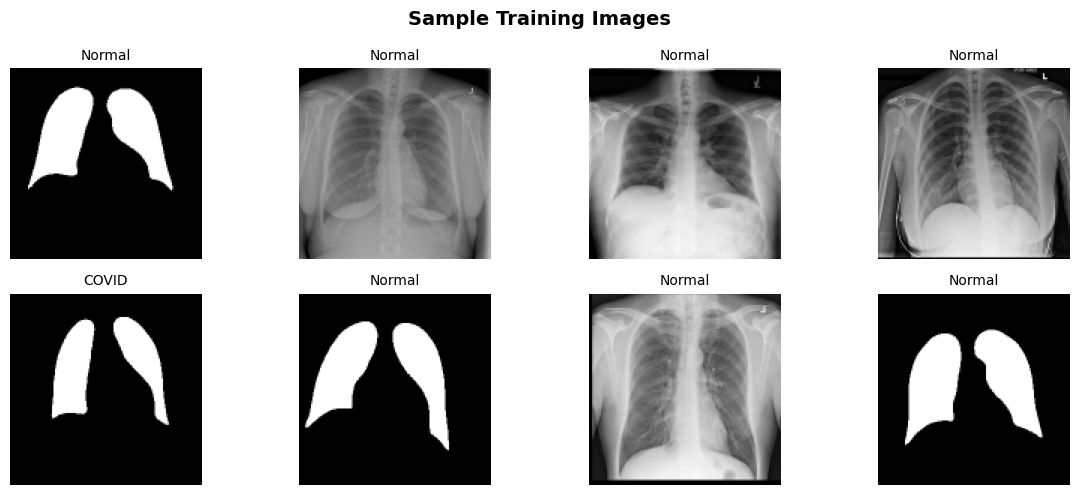

In [ ]:
plt.figure(figsize=(12, 5))
plt.suptitle("Sample Training Images", fontsize=14, fontweight='bold')

for images, labels in train_ds.take(2):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])], fontsize=10)
        plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_size, img_size, 3)),

    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),


    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_12 (Rescaling)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,120,993 (8.09 MB)

 Trainable params: 2,120,993 (8.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import tensorflow as tf

# Early Stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

print("\nTraining model...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)


Training model...
Epoch 1/10
691/691 ━━━━━━━━━━━━━━━━━━━━ 36s 47ms/step - accuracy: 0.8170 - loss: 0.4012 - val_accuracy: 0.8662 - val_loss: 0.3191
Epoch 2/10
691/691 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.8778 - loss: 0.2907 - val_accuracy: 0.8901 - val_loss: 0.2683
Epoch 3/10
691/691 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.8981 - loss: 0.2448 - val_accuracy: 0.8943 - val_loss: 0.2547
Epoch 4/10
691/691 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.9117 - loss: 0.2140 - val_accuracy: 0.8968 - val_loss: 0.2507
Epoch 5/10
691/691 ━━━━━━━━━━━━━━━━━━━━ 30s 43ms/step - accuracy: 0.9223 - loss: 0.1867 - val_accuracy: 0.9024 - val_loss: 0.2527
Epoch 6/10
691/691 ━━━━━━━━━━━━━━━━━━━━ 44s 47ms/step - accuracy: 0.9345 - loss: 0.1604 - val_accuracy: 0.8977 - val_loss: 0.2532
Epoch 7/10
691/691 ━━━━━━━━━━━━━━━━━━━━ 37s 42ms/step - accuracy: 0.9451 - loss: 0.1374 - val_accuracy: 0.9053 - val_loss: 0.2869


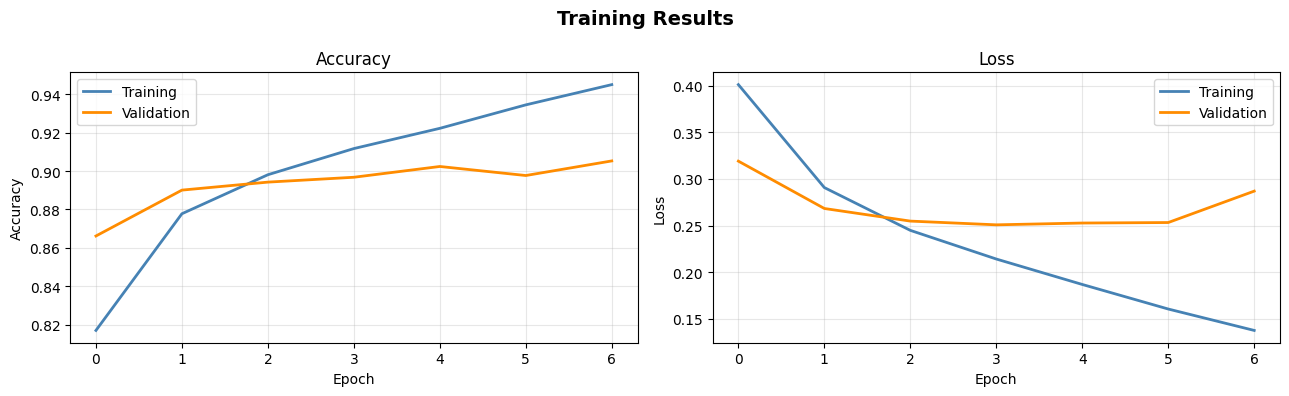

In [ ]:
acc     = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss    = history.history['loss']
val_loss= history.history['val_loss']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Training Results", fontsize=14, fontweight='bold')

axes[0].plot(acc,     label='Training',   color='steelblue',  linewidth=2)
axes[0].plot(val_acc, label='Validation', color='darkorange', linewidth=2)
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(loss,     label='Training',   color='steelblue',  linewidth=2)
axes[1].plot(val_loss, label='Validation', color='darkorange', linewidth=2)
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()


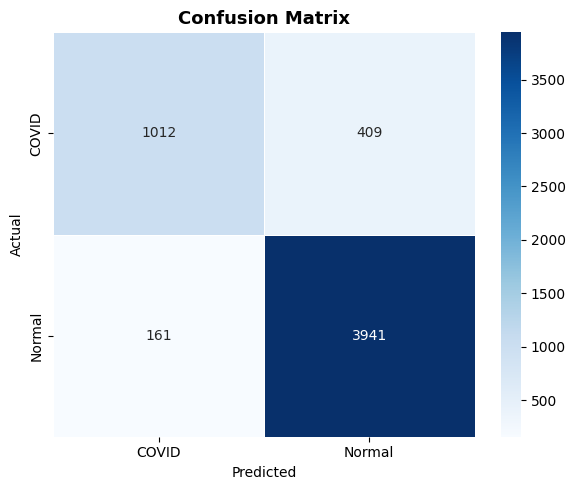


Classification Report:
              precision    recall  f1-score   support

       COVID       0.86      0.71      0.78      1421
      Normal       0.91      0.96      0.93      4102

    accuracy                           0.90      5523
   macro avg       0.88      0.84      0.86      5523
weighted avg       0.89      0.90      0.89      5523



In [ ]:
y_true, y_pred = [], []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend((preds > 0.5).astype(int).flatten())
    y_true.extend(labels.numpy().astype(int))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5)
plt.title('Confusion Matrix', fontsize=13, fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


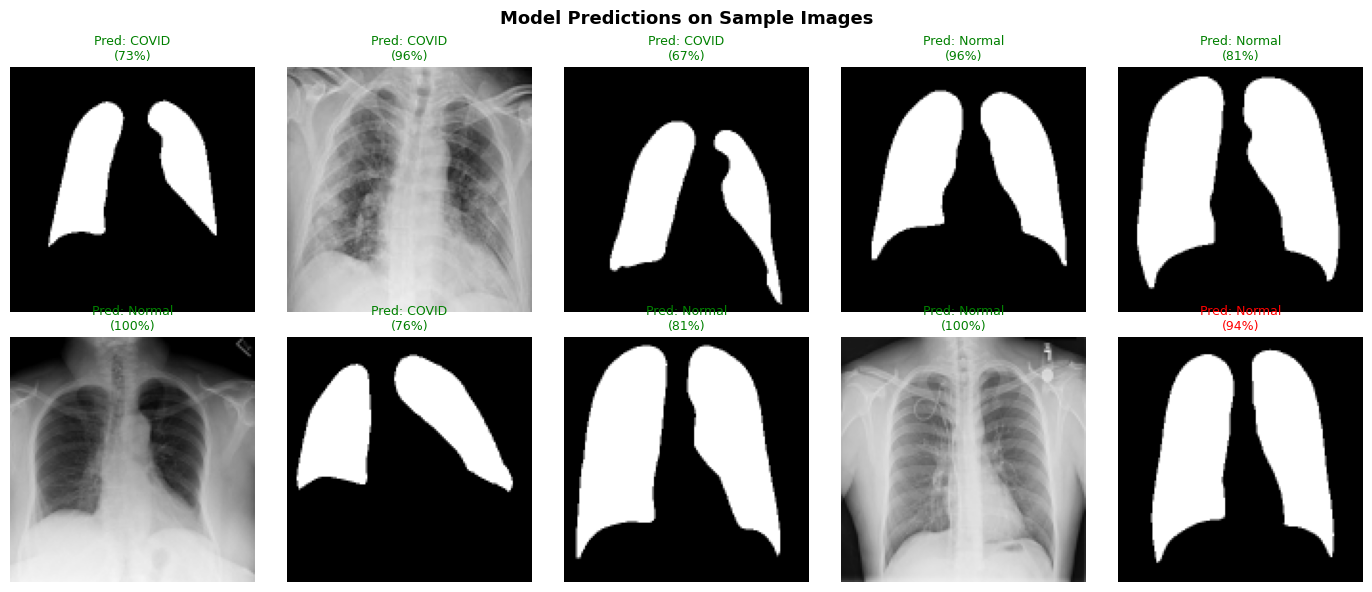

In [ ]:
plt.figure(figsize=(14, 6))
plt.suptitle("Model Predictions on Sample Images", fontsize=13, fontweight='bold')

for images, labels in val_ds.take(1):
    preds = model.predict(images, verbose=0)
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        pred_prob = preds[i][0]
        pred_label = class_names[1] if pred_prob > 0.5 else class_names[0]
        true_label = class_names[int(labels[i])]
        color = 'green' if pred_label == true_label else 'red'
        conf = preds[i][0] if preds[i] > 0.5 else 1 - preds[i][0]
        plt.title(f"Pred: {pred_label}\n({conf*100:.0f}%)",
                  color=color, fontsize=9)
        plt.axis('off')

plt.tight_layout()
plt.savefig('predictions.png', dpi=150)
plt.show()


In [ ]:
final_train_acc = acc[-1]
final_val_acc   = val_acc[-1]
final_train_loss= loss[-1]
final_val_loss  = val_loss[-1]

print("\n" + "="*45)
print("         FINAL RESULTS SUMMARY")
print("="*45)
print(f"  Train Accuracy     : {final_train_acc*100:.2f}%")
print(f"  Validation Accuracy: {final_val_acc*100:.2f}%")
print(f"  Train Loss         : {final_train_loss:.4f}")
print(f"  Validation Loss    : {final_val_loss:.4f}")
print("="*45)

# Save model
model.save('covid_model.h5')
print("\nModel saved: covid_model.h5")


         FINAL RESULTS SUMMARY
  Train Accuracy     : 94.51%
  Validation Accuracy: 90.53%
  Train Loss         : 0.1374
  Validation Loss    : 0.2869

Model saved: covid_model.h5
